# **Import Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")

# **Load and Explore Data**

In [ ]:
df = pd.read_csv('/content/quikr_car.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        892 non-null    object
 1   company     892 non-null    object
 2   year        892 non-null    object
 3   Price       892 non-null    object
 4   kms_driven  840 non-null    object
 5   fuel_type   837 non-null    object
dtypes: object(6)
memory usage: 41.9+ KB


,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel


In [ ]:
df.describe()

,name,company,year,Price,kms_driven,fuel_type
count,892,892,892,892,840,837
unique,525,48,61,274,258,3
top,Honda City,Maruti,2015,Ask For Price,"45,000 kms",Petrol
freq,13,235,117,35,30,440


In [ ]:
print(f"Dataset Shape: {df.shape}\n")
print("Missing Values per Column:")
print(df.isnull().sum())

Dataset Shape: (892, 6)

Missing Values per Column:
name           0
company        0
year           0
Price          0
kms_driven    52
fuel_type     55
dtype: int64


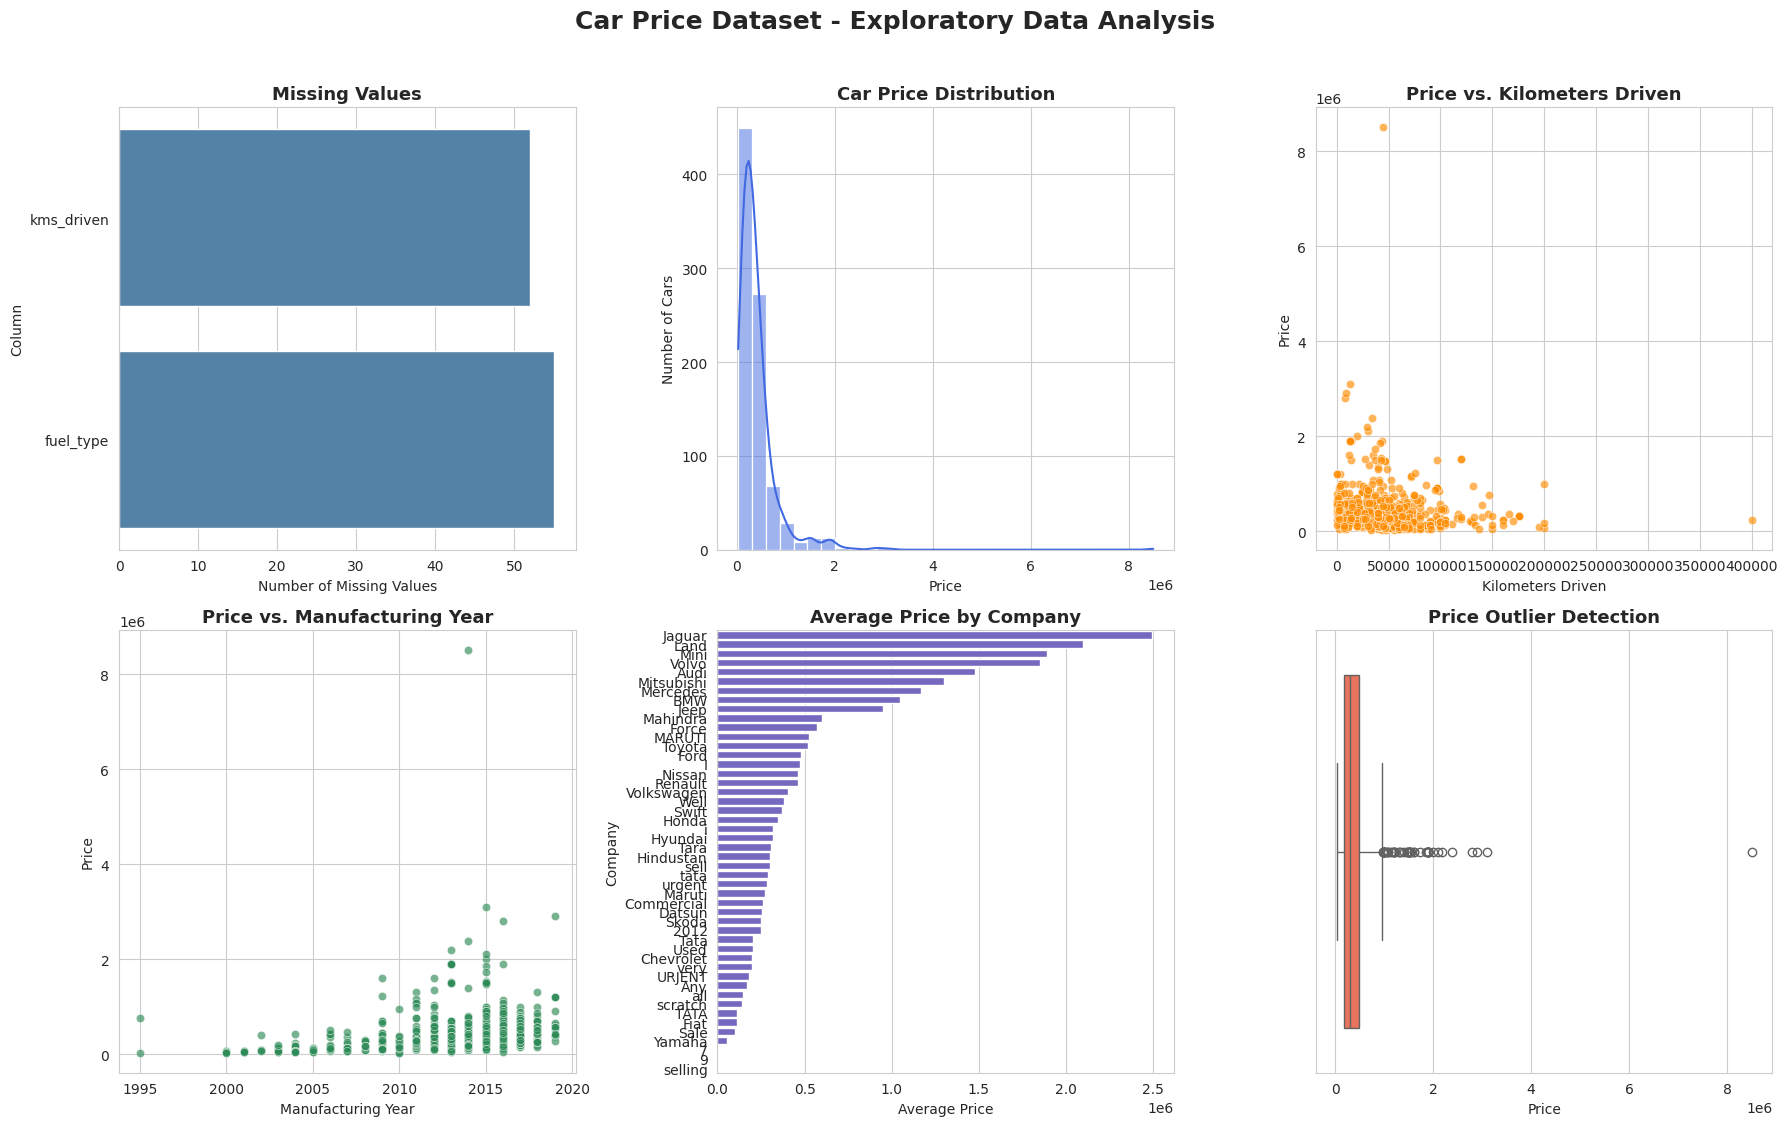

In [ ]:
sns.set_style("whitegrid")


# Prepare columns for visualization

# Year
year_numeric = pd.to_numeric(df["year"], errors="coerce")

# Price
price_numeric = (
    df["Price"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(r"[^\d.]", "", regex=True)
)

price_numeric = pd.to_numeric(price_numeric, errors="coerce")

# Kilometers driven
kms_numeric = (
    df["kms_driven"]
    .astype(str)
    .str.replace(",", "", regex=False)
    .str.replace(r"[^\d.]", "", regex=True)
)

kms_numeric = pd.to_numeric(kms_numeric, errors="coerce")


fig, axes = plt.subplots(2, 3, figsize=(18, 11))


# 1. Missing Values
missing = df.isnull().sum()
missing = missing[missing > 0]

if len(missing) > 0:
    sns.barplot(
        x=missing.values,
        y=missing.index,
        ax=axes[0, 0],
        color="steelblue"
    )

    axes[0, 0].set_title(
        "Missing Values",
        fontsize=13,
        fontweight="bold"
    )
    axes[0, 0].set_xlabel("Number of Missing Values")
    axes[0, 0].set_ylabel("Column")
else:
    axes[0, 0].text(
        0.5, 0.5,
        "No Missing Values",
        ha="center",
        va="center",
        fontsize=14
    )
    axes[0, 0].set_title("Missing Values")


# 2. Price Distribution
sns.histplot(
    price_numeric.dropna(),
    bins=30,
    kde=True,
    color="royalblue",
    ax=axes[0, 1]
)

axes[0, 1].set_title(
    "Car Price Distribution",
    fontsize=13,
    fontweight="bold"
)
axes[0, 1].set_xlabel("Price")
axes[0, 1].set_ylabel("Number of Cars")


# 3. Price vs Kilometers Driven
sns.scatterplot(
    x=kms_numeric,
    y=price_numeric,
    alpha=0.65,
    color="darkorange",
    ax=axes[0, 2]
)

axes[0, 2].set_title(
    "Price vs. Kilometers Driven",
    fontsize=13,
    fontweight="bold"
)
axes[0, 2].set_xlabel("Kilometers Driven")
axes[0, 2].set_ylabel("Price")


# 4. Price vs Manufacturing Year
sns.scatterplot(
    x=year_numeric,
    y=price_numeric,
    alpha=0.65,
    color="seagreen",
    ax=axes[1, 0]
)

axes[1, 0].set_title(
    "Price vs. Manufacturing Year",
    fontsize=13,
    fontweight="bold"
)
axes[1, 0].set_xlabel("Manufacturing Year")
axes[1, 0].set_ylabel("Price")


# 5. Average Price by Company
company_price = pd.DataFrame({
    "company": df["company"],
    "price": price_numeric
})

company_avg_price = (
    company_price
    .groupby("company")["price"]
    .mean()
    .sort_values(ascending=False)
)

sns.barplot(
    x=company_avg_price.values,
    y=company_avg_price.index,
    ax=axes[1, 1],
    color="slateblue"
)

axes[1, 1].set_title(
    "Average Price by Company",
    fontsize=13,
    fontweight="bold"
)
axes[1, 1].set_xlabel("Average Price")
axes[1, 1].set_ylabel("Company")


# 6. Price Boxplot - Outlier Detection
sns.boxplot(
    x=price_numeric,
    color="tomato",
    ax=axes[1, 2]
)

axes[1, 2].set_title(
    "Price Outlier Detection",
    fontsize=13,
    fontweight="bold"
)
axes[1, 2].set_xlabel("Price")


# Overall formatting
plt.suptitle(
    "Car Price Dataset - Exploratory Data Analysis",
    fontsize=18,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()

plt.show()

# **Data Preprocessing**

In [ ]:
print("Original Dataset Shape:", df.shape)
print("\nOriginal Missing Values:")
print(df.isnull().sum())


# 2. Clean Price (Target Variable)

# Remove commas and non-numeric characters
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.strip()
    .str.replace(",", "", regex=False)
    .str.replace(r"[^\d.]", "", regex=True)
)

# Convert to numeric
# "Ask For Price" becomes NaN
df["Price"] = pd.to_numeric(
    df["Price"],
    errors="coerce"
)

# Remove rows where target Price is unavailable
df = df.dropna(subset=["Price"]).copy()


# 3. Clean Year
# Convert valid years to numeric
df["year"] = pd.to_numeric(
    df["year"],
    errors="coerce"
)

# Keep only realistic manufacturing years
# Invalid values such as:
# '150k', 'TOUR', 'Zest', 'sale', 'Eon', etc.
# become NaN
df.loc[
    ~df["year"].between(1980, 2026),
    "year"
] = np.nan

# Remove rows with invalid/missing year
df = df.dropna(subset=["year"]).copy()

# Convert year to integer
df["year"] = df["year"].astype(int)


# 4. Clean Kilometers Driven
df["kms_driven"] = (
    df["kms_driven"]
    .astype(str)
    .str.strip()
    .str.replace(",", "", regex=False)
    .str.replace(r"[^\d.]", "", regex=True)
)

df["kms_driven"] = pd.to_numeric(
    df["kms_driven"],
    errors="coerce"
)


# 5. Clean Fuel Type
# Standardize text values
df["fuel_type"] = (
    df["fuel_type"]
    .astype("string")
    .str.strip()
    .str.title()
)


# 6. Remove Duplicate Rows
duplicates = df.duplicated().sum()

print("\nDuplicate Rows Found:", duplicates)

df = df.drop_duplicates().reset_index(drop=True)


# 7. Final Dataset Information
print("\n========================================")
print("FINAL DATASET INFORMATION")
print("========================================")

print("Dataset Shape:", df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nNumber of Duplicate Rows:", df.duplicated().sum())

print("\nFirst 5 Rows:")
display(df.head())

Original Dataset Shape: (892, 6)

Original Missing Values:
name           0
company        0
year           0
Price          0
kms_driven    52
fuel_type     55
dtype: int64

Duplicate Rows Found: 92

FINAL DATASET INFORMATION
Dataset Shape: (727, 6)

Data Types:
name                  object
company               object
year                   int64
Price                float64
kms_driven           float64
fuel_type     string[python]
dtype: object

Missing Values:
name          0
company       0
year          0
Price         0
kms_driven    2
fuel_type     3
dtype: int64

Number of Duplicate Rows: 0

First 5 Rows:


,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,80000.0,45000.0,Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,425000.0,40.0,Diesel
2,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,325000.0,28000.0,Petrol
3,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,575000.0,36000.0,Diesel
4,Ford Figo,Ford,2012,175000.0,41000.0,Diesel


# **Feature and Target Selection**

In [ ]:
X = df.drop("Price", axis=1)
y = df["Price"]

In [ ]:
print("Features:")
display(X.head())

print("\nTarget:")
display(y.head())

Features:


,name,company,year,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,45000.0,Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,40.0,Diesel
2,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,28000.0,Petrol
3,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,36000.0,Diesel
4,Ford Figo,Ford,2012,41000.0,Diesel



Target:


,Price
0,80000.0
1,425000.0
2,325000.0
3,575000.0
4,175000.0


# **Train Test Split**

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (581, 5)
Testing data: (146, 5)


# **Defining Preprocessing pipeline**

In [ ]:
numeric_features = [
    "year",
    "kms_driven"
]

categorical_features = [
    "name",
    "company",
    "fuel_type"
]

In [ ]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=2
            )
        )
    ]
)

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# **Defining Models**

In [ ]:
models = {
    "Linear Regression": LinearRegression(),

    "Ridge Regression": Ridge(),

    "Random Forest": RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}

# **Hyperparameter Tuning**

In [ ]:
# LINEAR REGRESSION
linear_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)
if 'fuel_type' in X_train.columns:
    X_train['fuel_type'] = X_train['fuel_type'].astype(object).replace(pd.NA, np.nan)
if 'fuel_type' in X_test.columns:
    X_test['fuel_type'] = X_test['fuel_type'].astype(object).replace(pd.NA, np.nan)

linear_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['year', 'kms_driven']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 min_frequency=2))]),
                                                  ['name', 'company',
                                                   'fuel_type'])])),
                ('model', LinearRegression())])

In [ ]:
# RIDGE REGRESSION
if 'fuel_type' in X_train.columns:
    X_train['fuel_type'] = X_train['fuel_type'].astype(object).replace(pd.NA, np.nan)
if 'fuel_type' in X_test.columns:
    X_test['fuel_type'] = X_test['fuel_type'].astype(object).replace(pd.NA, np.nan)

ridge_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge())
    ]
)

ridge_params = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

ridge_grid = GridSearchCV(
    ridge_pipeline,
    ridge_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

ridge_grid.fit(X_train, y_train)

print("Best Ridge Parameters:")
print(ridge_grid.best_params_)

Best Ridge Parameters:
{'model__alpha': 1}


In [ ]:
# RANDOM FOREST
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)
rf_params = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}
rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

print("Best CV RMSE:")
print(-rf_grid.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Random Forest Parameters:
{'model__max_depth': 20, 'model__min_samples_leaf': 1, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best CV RMSE:
253018.49704147564


In [ ]:
# GRADIENT BOOSTING
gb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                random_state=42
            )
        )
    ]
)
gb_params = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__min_samples_split": [2, 5]
}
gb_grid = GridSearchCV(
    gb_pipeline,
    gb_params,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
    verbose=1
)

gb_grid.fit(X_train, y_train)

print("Best Gradient Boosting Parameters:")
print(gb_grid.best_params_)

print("Best CV RMSE:")
print(-gb_grid.best_score_)

Fitting 5 folds for each of 36 candidates, totalling 180 fits
Best Gradient Boosting Parameters:
{'model__learning_rate': 0.1, 'model__max_depth': 2, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Best CV RMSE:
264949.7232467326


# **Evaluation And Best Model Selection**

In [ ]:
linear_pipeline.fit(X_train, y_train)

linear_pred = linear_pipeline.predict(X_test)
ridge_pred = ridge_grid.predict(X_test)
rf_pred = rf_grid.predict(X_test)
gb_pred = gb_grid.predict(X_test)

In [ ]:
def evaluate_model(name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [ ]:
results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        linear_pred
    )
)

results.append(
    evaluate_model(
        "Ridge Regression",
        y_test,
        ridge_pred
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        rf_pred
    )
)

results.append(
    evaluate_model(
        "Gradient Boosting",
        y_test,
        gb_pred
    )
)

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

results_df

,Model,MAE,RMSE,R2 Score
0,Linear Regression,206028.531663,718390.955253,0.162303
1,Ridge Regression,204732.355912,721070.386177,0.156042
2,Random Forest,201532.666761,732210.968331,0.129763
3,Gradient Boosting,211735.319057,740522.583688,0.109894


# **Selecting Best Model**

In [ ]:
best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)

Best Model: Linear Regression


In [ ]:
trained_models = {
    "Linear Regression": linear_pipeline,
    "Ridge Regression": ridge_grid.best_estimator_,
    "Random Forest": rf_grid.best_estimator_,
    "Gradient Boosting": gb_grid.best_estimator_
}

best_model = trained_models[best_model_name]

# **Actual VS Predicted Value**

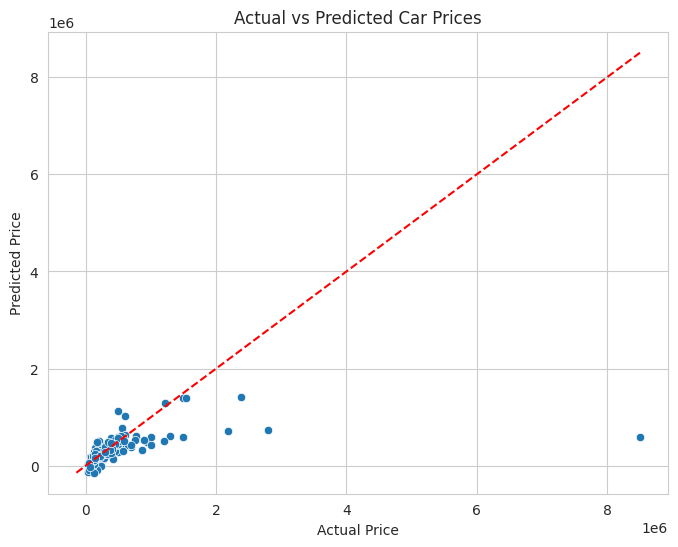

In [ ]:
best_predictions = best_model.predict(X_test)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions
)

plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Car Prices")

# Perfect prediction line
min_price = min(y_test.min(), best_predictions.min())
max_price = max(y_test.max(), best_predictions.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    color="red",
    linestyle="--"
)

plt.show()

# **Prediction Error Distribution**

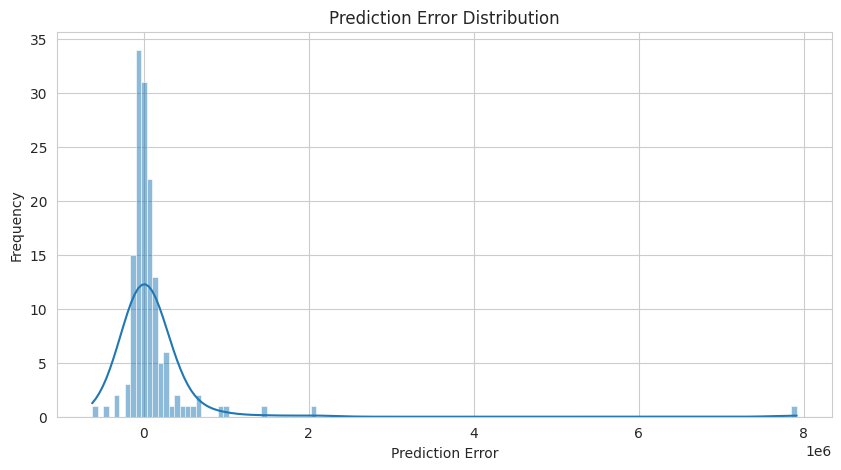

In [ ]:
errors = y_test - best_predictions

plt.figure(figsize=(10, 5))

sns.histplot(errors, kde=True)

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

# **Evaluation Metrics for Best Model**

In [ ]:
best_mae = mean_absolute_error(y_test, best_predictions)

best_rmse = np.sqrt(
    mean_squared_error(y_test, best_predictions)
)

best_r2 = r2_score(
    y_test,
    best_predictions
)

print("Best Model:", best_model_name)
print("----------------------------")
print("MAE :", best_mae)
print("RMSE:", best_rmse)
print("R²  :", best_r2)

Best Model: Linear Regression
----------------------------
MAE : 206028.53166332623
RMSE: 718390.9552530351
R²  : 0.1623028723208163


# **Prediction on New Data**

In [ ]:
new_car = pd.DataFrame({
    "name": ["Maruti Swift"],
    "company": ["Maruti"],
    "year": [2015],
    "kms_driven": [450000],
    "fuel_type": ["Petrol"]
})

new_car

,name,company,year,kms_driven,fuel_type
0,Maruti Swift,Maruti,2015,450000,Petrol


In [ ]:
predicted_price = best_model.predict(new_car)

print(
    f"Predicted Car Price: {predicted_price[0]:.2f}"
)

Predicted Car Price: 150658.62
